# ARTI 403 Lab 2 Solution

Sampling, quantization, arithmetic, and bitwise set operations on the supplied grayscale images.

In [1]:
from pathlib import Path
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

image_dir = Path('images')
if not image_dir.is_dir():
    raise FileNotFoundError('Run this notebook from the lab2_Package folder containing images/.')

def show_images(images, titles):
    fig, axes = plt.subplots(1, len(images), figsize=(5 * len(images), 4), squeeze=False)
    for ax, image, title in zip(axes[0], images, titles):
        ax.imshow(image, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
        ax.set_title(title)
        ax.axis('off')
    fig.tight_layout()
    plt.show()


## Task 1 Sampling and Quantization

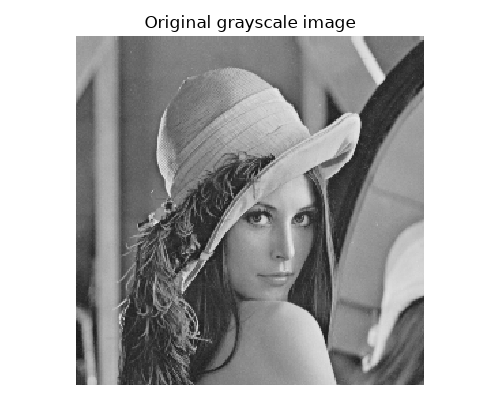

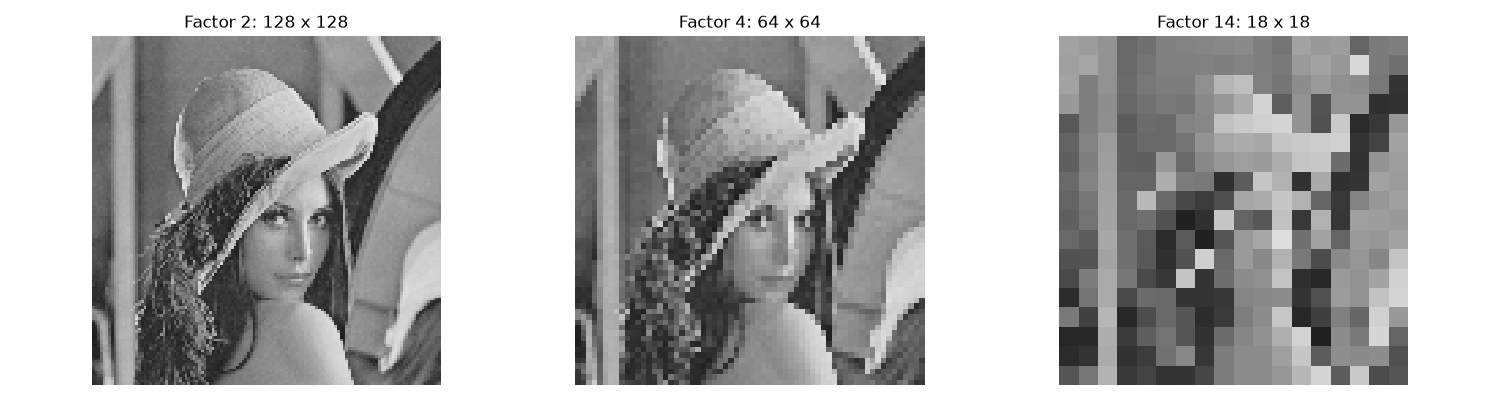

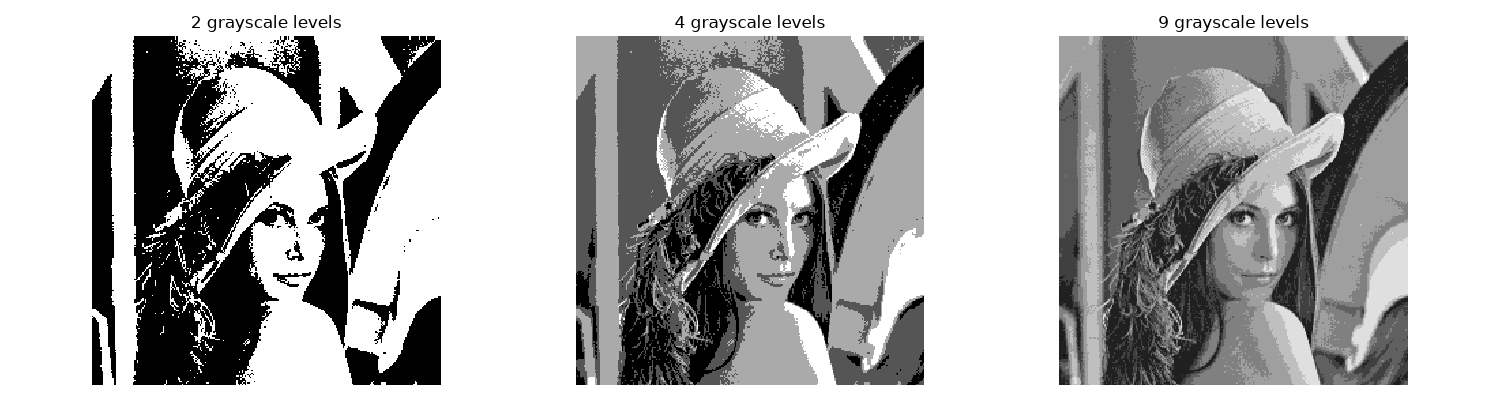

Requested levels: 2; levels present in this image: 2
Requested levels: 4; levels present in this image: 4
Requested levels: 9; levels present in this image: 9


In [2]:
def sample_image(image, factor):
    """Downsample using nearest-neighbor interpolation, as in the manual."""
    height, width = image.shape[:2]
    if not isinstance(factor, (int, np.integer)) or not 1 <= factor <= min(height, width):
        raise ValueError('factor must be an integer between 1 and the smaller image dimension')
    return cv2.resize(image, (width // factor, height // factor), interpolation=cv2.INTER_NEAREST)

def quantize_image(image, levels):
    """Map uint8 intensities into exactly levels possible output values."""
    if not isinstance(levels, (int, np.integer)) or not 2 <= levels <= 256:
        raise ValueError('levels must be an integer from 2 to 256')
    # Promote before multiplication to prevent uint8 overflow.
    bins = image.astype(np.uint16) * levels // 256
    return np.rint(bins * (255.0 / (levels - 1))).astype(np.uint8)

original_image = cv2.imread(str(image_dir / 'lena_gray_256.tif'), cv2.IMREAD_GRAYSCALE)
if original_image is None:
    raise FileNotFoundError(f'Unable to load {image_dir / "lena_gray_256.tif"}')

show_images([original_image], ['Original grayscale image'])
sampling_factors = [2, 4, 14]
sampled_images = [sample_image(original_image, factor) for factor in sampling_factors]
show_images(sampled_images, [f'Factor {f}: {im.shape[1]} x {im.shape[0]}'
                            for f, im in zip(sampling_factors, sampled_images)])

quantization_levels_list = [2, 4, 9]
quantized_images = [quantize_image(original_image, levels) for levels in quantization_levels_list]
show_images(quantized_images, [f'{levels} grayscale levels' for levels in quantization_levels_list])
for levels, image in zip(quantization_levels_list, quantized_images):
    print(f'Requested levels: {levels}; levels present in this image: {len(np.unique(image))}')


### Observations

Increasing the sampling factor reduces the number of pixels: factors 2, 4, and 14 reduce the 256 by 256 image to 128 by 128, 64 by 64, and 18 by 18 pixels. Fine details are lost and the enlarged display looks blockier.

Reducing quantization levels preserves the image dimensions but reduces intensity detail. Two levels give a black-and-white image; four levels show stronger banding than nine. Sampling and quantization are varied separately so their effects can be compared. All plots use the same intensity range of 0 to 255.

The manual's integer step `256 // levels` does not enforce the requested number of levels when levels does not divide 256. For example, with 9 levels it allows 10 output values. The corrected function uses 9 bins and maps them evenly across the display range.


## Task 2 Arithmetic and Set Operations

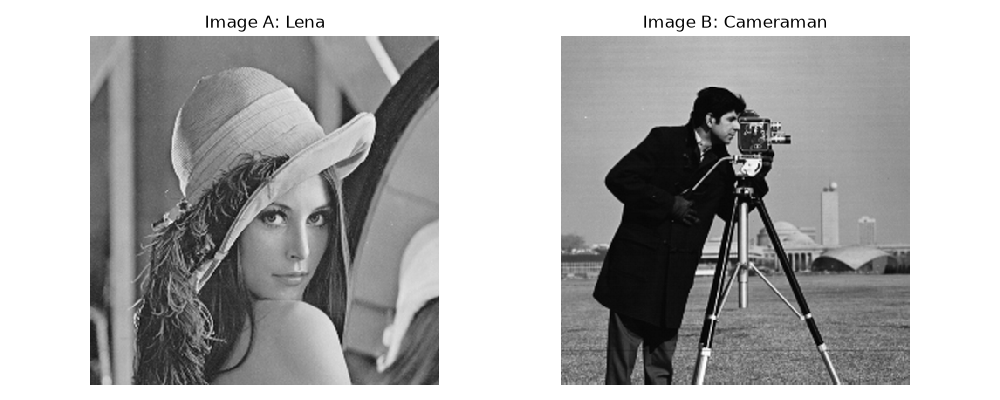

In [3]:
resize = (400, 400)
with Image.open(image_dir / 'lena_gray_256.tif') as image:
    im1arr = np.array(image.convert('L').resize(resize, Image.Resampling.LANCZOS))
with Image.open(image_dir / 'cameraman.tif') as image:
    im2arr = np.array(image.convert('L').resize(resize, Image.Resampling.LANCZOS))
show_images([im1arr, im2arr], ['Image A: Lena', 'Image B: Cameraman'])


### Arithmetic Operations

Use saturated uint8 arithmetic: negative results become 0 and values above 255 become 255. Direct NumPy addition on uint8 arrays wraps around and would give incorrect brightness values for this convention.

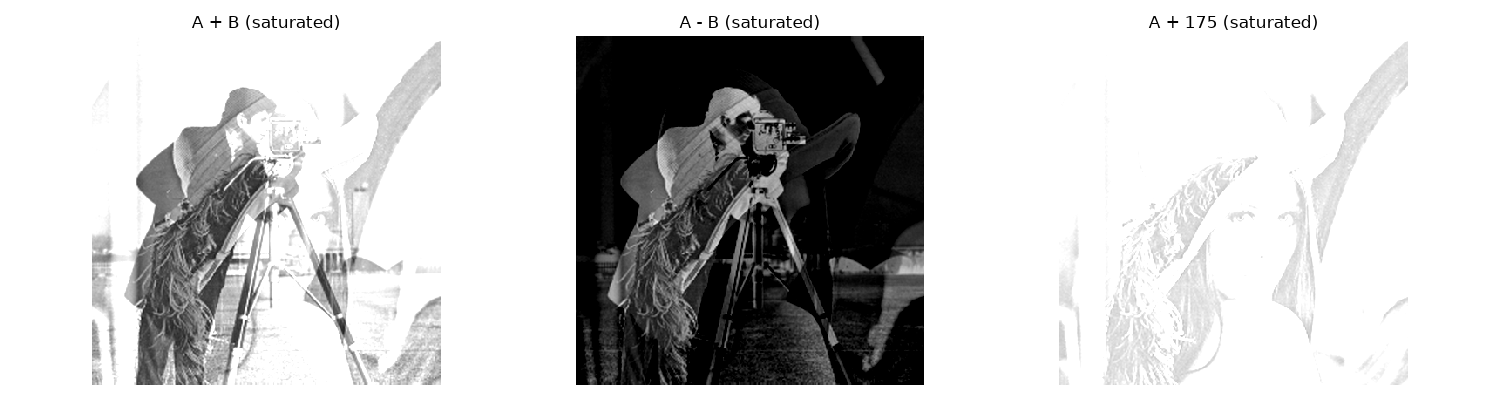

In [4]:
addition = cv2.add(im1arr, im2arr)
subtraction = cv2.subtract(im1arr, im2arr)
addition_constant = np.clip(im1arr.astype(np.int16) + 175, 0, 255).astype(np.uint8)
show_images([addition, subtraction, addition_constant],
            ['A + B (saturated)', 'A - B (saturated)', 'A + 175 (saturated)'])


### Set and Logical Operations

Use the two supplied grayscale images; the example files A.png and B.png are absent from this package. Following the manual's bitwise OR example, treat each grayscale pixel as an 8-bit pattern. Set difference is A AND NOT B, symmetric difference is XOR, and intersection is AND. These are bitwise operations on grayscale values, not thresholded binary masks or fuzzy grayscale min/max operations.


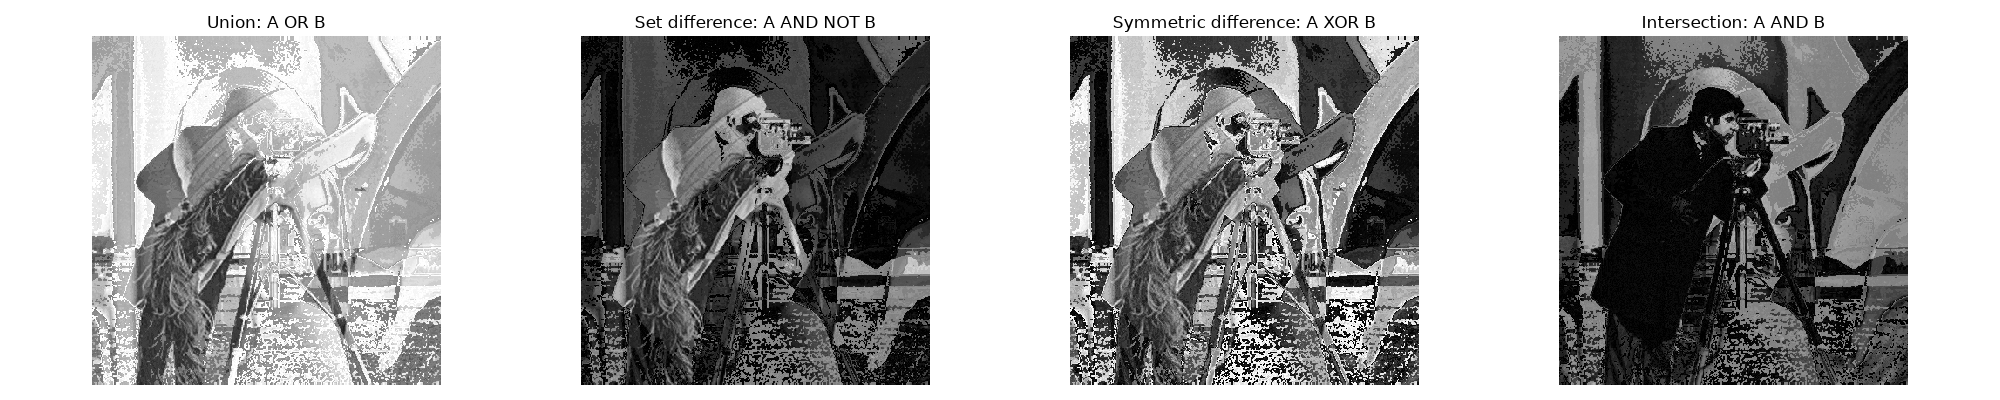

In [5]:
union = cv2.bitwise_or(im1arr, im2arr)
set_difference = cv2.bitwise_and(im1arr, cv2.bitwise_not(im2arr))
symmetric_difference = cv2.bitwise_xor(im1arr, im2arr)
intersection = cv2.bitwise_and(im1arr, im2arr)
show_images([union, set_difference, symmetric_difference, intersection],
            ['Union: A OR B', 'Set difference: A AND NOT B',
             'Symmetric difference: A XOR B', 'Intersection: A AND B'])


### Observations

Subtraction highlights pixels where A is brighter than B and clips negative differences to black. Adding 175 brightens A and saturates many pixels to white. Bitwise set difference retains the bits present in A but absent from B; XOR retains bits that differ; AND retains shared bits. Their visual patterns depend on individual intensity bits, so they do not directly represent geometric object overlap without binary masks.
